# Delano diagrams: first order layout of a lithography lens

Delano's $y$-$\bar y$ diagram plots the height $\bar y$ of the paraxial
chief ray against the height $y$ of the paraxial marginal ray at every lens
(or surface). A system becomes a polygon, and all of its first order
properties can be read off it: powers, spacings, stop and pupils,
telecentricity, conjugates, cardinal points. The other way round, a lens can
be *drawn* as a polygon and then built from it. This is how complex systems
such as lithographic projection lenses are laid out before any surface is
bent (Delano 1963; Shack 1973; Matsuyama, Ohmura and Williamson, "The
lithographic lens: its history and evolution", Proc. SPIE 6154, 2006).

This notebook

1. reads the diagram of Caldwell's KrF lens (`DelanoDiagram.from_system()`),
2. shows the rules of the diagram with a three lens relay,
3. lays out a new KrF projection lens in the diagram: **20 elements, 1 m from
   object to wafer, magnification −0.25, NA 0.7**, telecentric on both sides,
   with a flat field (Petzval sum zero) — first as a hand drawn sketch, then
   polished with `delano.refine()`,
4. turns the thin lens layout into fused silica singlets with the same first
   order properties (`delano.thicken()`),
5. corrects the aberrations with real rays (`lens_optimization.LensOptimizer`
   with analytic Jacobians, five aspheric surfaces, clearances, an air space
   for the NA stop, the real NA 0.7) and asks how much the starting design
   matters, with Caldwell's lens as a second start,
6. asks where more aspheres should go: the predicted gain of an asphere on
   each surface, against the pupil closeness of the surfaces,
7. adds five aspheres there and polishes with
   `lens_optimization.DampedLeastSquares`, with the clearances as Lagrange
   multiplier constraints, and reads off what each clearance costs,
8. checks the corrected lens: wavefront, spots, distortion, telecentricity,
   Zernike terms,
9. finds the best axial position of the NA stop (an iris) for NAs from 0.35
   to 0.7.

Conventions (module `pyoptics.delano`): points $P = (\bar y, y)$, reduced
slopes $\omega = n u$, Lagrange invariant $H = n(\bar u y - u \bar y)$, as
`raytrace.Paraxial.lagrange`. Lengths in mm.

In [1]:
import time

import numpy as np
import matplotlib.pyplot as plt

from pyoptics import raytrace as rt
from pyoptics import lens_optimization as lo
from pyoptics.delano import DelanoDiagram, refine, thicken

plt.rcParams.update({"figure.dpi": 80, "font.size": 11})
t_start = time.time()

## 1. The diagram of a real lens

`DelanoDiagram.from_system()` takes the paraxial marginal and chief rays of a
`raytrace.System`: one point per surface vertex, plus the object and the
image point. Caldwell's all fused silica KrF lens (21 elements, NA 0.56, 4x,
1 m) as an example:

44 points: object, 42 surfaces, image; H = -6.2702 mm
powers from the corners vs. (n' - n)/R: max. difference 1.3e-16 1/mm
spaces from the triangle areas vs. the thicknesses: max. difference 7.5e-14 mm
magnification -0.25000 (paraxial -0.25000), NA 0.5359 (paraxial 0.5359), length 1000.01 mm
stop (y axis crossing) 701.8 mm behind the object, surface 30 at 701.8 mm; entrance pupil 10.0 m, exit pupil -2.6 m from the object


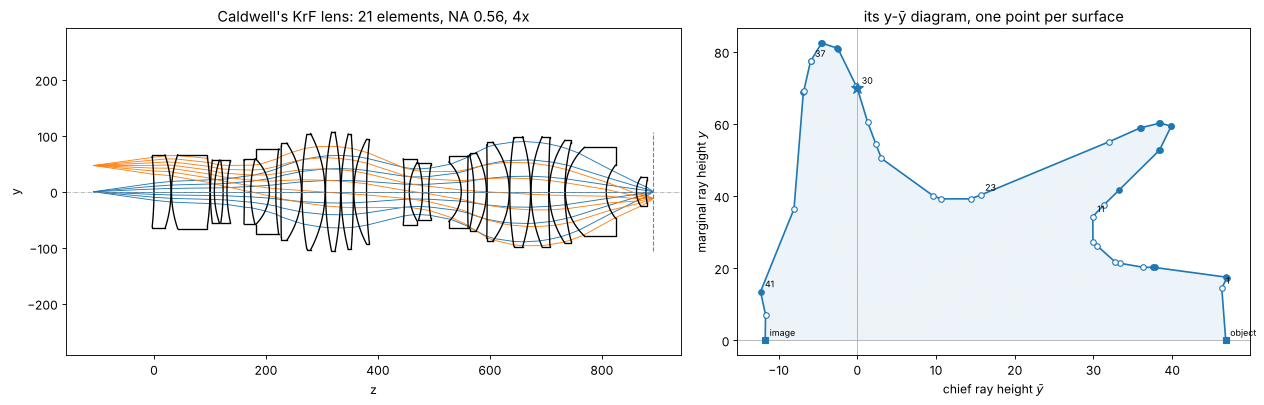

In [2]:
caldwell = rt.caldwell_krf_lens()
dc = DelanoDiagram.from_system(caldwell)
p = caldwell.paraxial()

fig, axes = plt.subplots(1, 2, figsize=(16, 5.2), gridspec_kw={"width_ratios": [1.2, 1]})
caldwell.draw(axes[0], fields=[0.0, caldwell.max_field])
axes[0].set_title("Caldwell's KrF lens: 21 elements, NA 0.56, 4x")
dc.plot(axes[1], annotate=False, areas=True)
for k in [0, 1, 11, 23, 30, 37, 41, 43]:
    axes[1].annotate(dc.labels[k], (dc.ybar[k], dc.y[k]), xytext=(4, 4), textcoords="offset points",
                     fontsize=8)
axes[1].set_title("its y-ȳ diagram, one point per surface")
fig.tight_layout()

n_s = caldwell.n*caldwell.sigma
powers = np.array([s.paraxial_power(n_s[i], n_s[i + 1]) for i, s in enumerate(caldwell.surfaces)])
print(f"{len(dc)} points: object, 42 surfaces, image; H = {dc.H:.4f} mm")
print(f"powers from the corners vs. (n' - n)/R: max. difference {np.max(abs(dc.power - powers)):.1e} 1/mm")
print(f"spaces from the triangle areas vs. the thicknesses: max. difference "
      f"{np.max(abs(dc.thickness[1:-1] - [s.thickness for s in caldwell.surfaces[:-1]])):.1e} mm")
print(f"magnification {dc.magnification:.5f} (paraxial {p.magnification:.5f}), "
      f"NA {dc.NA[1]:.4f} (paraxial {p.na:.4f}), length {dc.length:.2f} mm")
pu = dc.pupils()
print(f"stop (y axis crossing) {pu.stop[0]:.1f} mm behind the object, surface 30 at "
      f"{caldwell.object_distance + caldwell.vertex_z[29]:.1f} mm; entrance pupil "
      f"{pu.entrance/1e3:.1f} m, exit pupil {pu.exit/1e3:.1f} m from the object")

How to read it:

- The polygon starts at the **object** on the $\bar y$ axis ($y = 0$, $\bar y$
  = object height 46.8 mm) and ends at the **image** ($\bar y = -11.7$ mm). It
  crosses the $y$ axis ($\bar y = 0$) once, at the **aperture stop**
  (star), here at surface 30.
- The first and the last edges are almost vertical: the chief ray is almost
  parallel to the axis in object and image space, the lens is (nearly)
  **telecentric** on both sides. The extended edges meet $\bar y = 0$ at the
  pupils, 9 m in front of and 2.6 m behind the lens.
- Every edge is a space: the shaded triangle that it spans with the origin
  has the area $H\tau/2$, with the reduced thickness $\tau = t/n$. Long air
  spaces far from the origin are large triangles; a glass element is two
  corners close together.
- Every corner is a surface: its power is the change of direction,
  $\phi_k = -(\bar\omega_{k-1}\omega_k - \omega_{k-1}\bar\omega_k)/H$. A
  convex corner (turning towards the origin) is positive (filled circles), a
  concave one negative (open circles). The same bend is a weak surface far
  from the origin and a strong one close to it.
- The shape is the classic one of lithography lenses: **bulges** (large
  beams, positive groups) and **waists** (small beams, negative groups)
  alternate. The waists correct the Petzval sum: the Petzval sum of thin
  lenses $\sum \phi_k/n_k$ does not depend on where a lens sits, but its
  contribution to the imaging, the bend of the marginal ray $y_k\phi_k$, does.
  Negative lenses in a waist (small $y$) flatten the field at little cost in
  power.

## 2. The rules, with three thin lenses

A double telecentric 4x relay of three thin lenses, drawn directly as a
polygon: object $(h, 0)$, a vertical edge up (telecentric object space), a
corner at the top, down to $(-h/4, y_3)$ and vertically down to the image
$(-h/4, 0)$. The Lagrange invariant follows from the object side NA,
$H = -\mathrm{NA}_\mathrm{obj}\,h$; `with_length()` scales all $y$ so that
the system is 1 m long (same NA, field and magnification).

focal lengths [793.2 202.4  91.1] mm; spaces [205.7 555.3 200.5  38.6] mm
thin lens system: magnification -0.2500, NA 0.7000, length 1000.0 mm, entrance/exit pupil at inf/-4.1e+17 mm (telecentric)
image of L1 in the last space: z = 1012.9 mm, magnification -0.250
image of L2 in the last space: z = 1128.5 mm, magnification -0.833


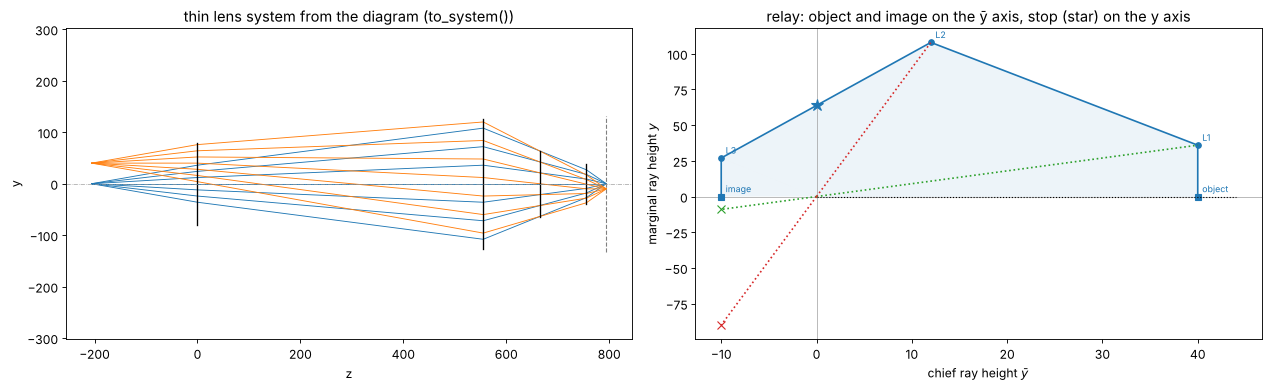

In [3]:
h = 40.0
relay = DelanoDiagram([h, h, 0.3*h, -0.25*h, -0.25*h], [0, 20, 60, 15, 0], -0.175*h,
                      labels=["object", "L1", "L2", "L3", "image"]).with_length(1000.0)
relay_system = relay.to_system(248.3e-6)
pr = relay_system.paraxial()
print("focal lengths", np.round(relay.focal_length, 1), "mm; spaces", np.round(relay.thickness, 1), "mm")
print(f"thin lens system: magnification {pr.magnification:.4f}, NA {pr.na:.4f}, "
      f"length {relay_system.object_distance + relay_system.image_z:.1f} mm, "
      f"entrance/exit pupil at {pr.ep_z:.1e}/{pr.xp_z:.1e} mm (telecentric)")

fig, axes = plt.subplots(1, 2, figsize=(16, 5))
relay_system.draw(axes[0], fields=[0.0, h])
axes[0].set_title("thin lens system from the diagram (to_system())")
relay.plot(axes[1], areas=True)
# conjugates lie on lines through the origin
axes[1].plot([0, 1.1*h], [0, 0], "k:", lw=1)
z_stop = relay.pupils().stop[0]
for k, c in [(1, "C2"), (2, "C3")]:
    z, m = relay.conjugate(3, k)
    q = m*relay.points[k]
    axes[1].plot([0, relay.ybar[k]], [0, relay.y[k]], ":", color=c)
    axes[1].plot([0, q[0]], [0, q[1]], ":", color=c)
    axes[1].plot(*q, "x", color=c, ms=8)
    print(f"image of {relay.labels[k]} in the last space: z = {z:.1f} mm, magnification {m:.3f}")
axes[1].set_title("relay: object and image on the ȳ axis, stop (star) on the y axis")
fig.tight_layout()

## 3. Specification and sketch of the new lens

The specification fixes the ends of the polygon:

| | in the diagram |
|---|---|
| magnification −0.25 | object at $(h, 0)$, image at $(-h/4, 0)$ |
| telecentric object and image space | first and last edges vertical: $\bar y_1 = h$, $\bar y_{20} = -h/4$ |
| NA 0.7 (object side 0.175) | $H = -0.175\,h$; the slopes of the first and last edges follow |
| 1 m object to wafer | scale all $y$ (`with_length()`) |
| image field radius 13.6 mm (a 26 × 8 mm scanner slit) | $h = 54.4$ mm |
| flat field | Petzval sum $\sum\phi_k/n = 0$ |

Everything in between is design. Rules for drawing the polygon:

- It has to wind around the origin in one sense (here counterclockwise):
  a step back in angle would be a negative distance.
- Distances are areas: a lens close to the origin gets little room.
- The last space is the working distance (more precisely, from the rear
  principal plane of the last lens to the wafer): $t = y_{20}/\mathrm{NA}$.
- Lenses carry diameters $2(|y| + |\bar y|)$; with 1 m length and NA 0.7 the
  largest are about 250 mm.

The sketch below has the structure of the lens of section 1 with fewer
elements: three positive field lenses (L1–L3, telecentric object space), a
first waist of three negative lenses (L4–L6), a bulge (L7–L10), a second
waist (L11–L13), and the last bulge with the stop (L14–L20), which does most
of the focusing to NA 0.7. It is written in units of $h$ for $\bar y$ and of
an arbitrary scale for $y$ (`with_length()` fixes it).

In [4]:
WL = 248.3e-6                     # KrF, mm
N_SIO2 = rt.fused_silica(248.3)
M, LENGTH, NA = -0.25, 1000.0, 0.7
R_FIELD = 13.6                    # image field radius
h = R_FIELD/abs(M)                # object height
H = -NA*abs(M)*h                  # Lagrange invariant

# (ybar/h, y) of object, L1...L20, image
SKETCH = np.array([(1, 0), (1, 0.08), (0.97, 0.15), (0.92, 0.21), (0.82, 0.21), (0.74, 0.20),
                   (0.66, 0.22), (0.60, 0.33), (0.52, 0.47), (0.42, 0.57), (0.32, 0.61),
                   (0.24, 0.53), (0.18, 0.46), (0.12, 0.45), (0.07, 0.58), (0.02, 0.74),
                   (-0.04, 0.86), (-0.10, 0.88), (-0.16, 0.74), (-0.21, 0.48), (-0.25, 0.10),
                   (-0.25, 0)])
labels = ["object"] + [f"L{k}" for k in range(1, 21)] + ["image"]
sketch = DelanoDiagram(h*SKETCH[:, 0], SKETCH[:, 1], H, labels=labels).with_length(LENGTH)


def summary(d, name):
    print(f"{name}: Petzval sum {d.petzval_sum(N_SIO2)*1e3:+.3f}/m, NA {d.NA[0]:.3f} -> {d.NA[1]:.3f}, "
          f"magnification {d.magnification:.3f}, length {d.length:.1f} mm, stop at "
          f"{d.pupils().stop[0]:.0f} mm")
    print("  f    [mm]", " ".join(f"{f:6.0f}" for f in d.focal_length))
    print("  space[mm]", " ".join(f"{t:6.1f}" for t in d.thickness))
    print("  y*phi[%] ", " ".join(f"{v:6.1f}" for v in 100*d.y[1:-1]*d.power))
    print("  semi diam", " ".join(f"{v:6.1f}" for v in d.heights()[1:-1]))


summary(sketch, "sketch")

sketch: Petzval sum +1.437/m, NA 0.175 -> 0.700, magnification -0.250, length 1000.0 mm, stop at 696 mm
  f    [mm]   2086   2419    199    156    -95   -301  20471   1575   1053    132    376    -93   -102   -883    452    343    306    528    782    535
  space[mm]   69.2   62.6   56.8   18.2    7.4   26.6   74.2   95.4   85.6   63.8   20.1   13.0   22.3   32.9   34.8   40.5   43.9   57.7   67.9   85.6   21.6
  y*phi[%]     0.6    0.9   16.0   20.3  -31.7  -11.1    0.2    4.5    8.2   69.8   21.3  -74.9  -66.5   -9.9   24.8   38.0   43.6   21.2    9.3    2.8
  semi diam   66.5   75.5   81.8   76.4   70.5   69.2   82.6   99.4  109.1  109.7   93.2   79.4   74.6   91.6  113.0  132.3  138.6  120.7   84.0   28.7


The sketch already has the intended signs and a small Petzval sum (a
Petzval radius of about 0.7 m). Its weak points are in the row "y*phi", the
bend $y_k\phi_k$ of the marginal ray at each lens (the whole lens bends it
by 0.875, from +0.175 to −0.7): L10 at the corner into the second waist and
L12, L13 in it bend it by about ±0.7 each and cancel, which costs
aberrations, while L1, L2 and L7 do almost nothing; and the spaces around
L5 and L12 are too short for real lenses.

`refine()` moves the points of the sketch (keeping the telecentric ends) to
a Petzval sum of zero, spaces of at least 25 mm, a working space of 40 mm,
semi diameters up to 125 mm and the signs of the sketch, while staying close
to it and spreading the bending of the marginal ray over the lenses. It is a
small least squares problem in the 38 free coordinates of the inner points
(seconds).

refined: Petzval sum +0.000/m, NA 0.175 -> 0.700, magnification -0.250, length 1000.0 mm, stop at 677 mm
  f    [mm]   1445   2018    727    188   -223   -123    403   1657    275    290   6282   -109   -110  -1219    331    251   2050    223    925   2354
  space[mm]   98.2   41.8   31.6   25.0   25.0   25.0   49.6  101.3  103.8   25.0   25.0   28.3   25.0   27.0   36.9   28.6   42.4   96.8   61.8   62.1   40.0
  y*phi[%]     1.2    1.2    4.0   16.8  -13.5  -26.2   12.2    4.3   32.6   29.6    1.2  -56.6  -58.5   -6.8   33.6   49.2    5.9   48.6    7.6    1.2
  semi diam   71.6   76.8   79.6   79.0   68.0   64.6   83.9  102.2  114.6  107.1   90.5   71.2   70.4   86.9  112.0  125.0  125.5  120.5   84.0   41.6
thin lens system: m = -0.25000, NA = 0.7000, length = 1000.00 mm, telecentric: pupils at -1.1e+18 and -1.2e+18 mm


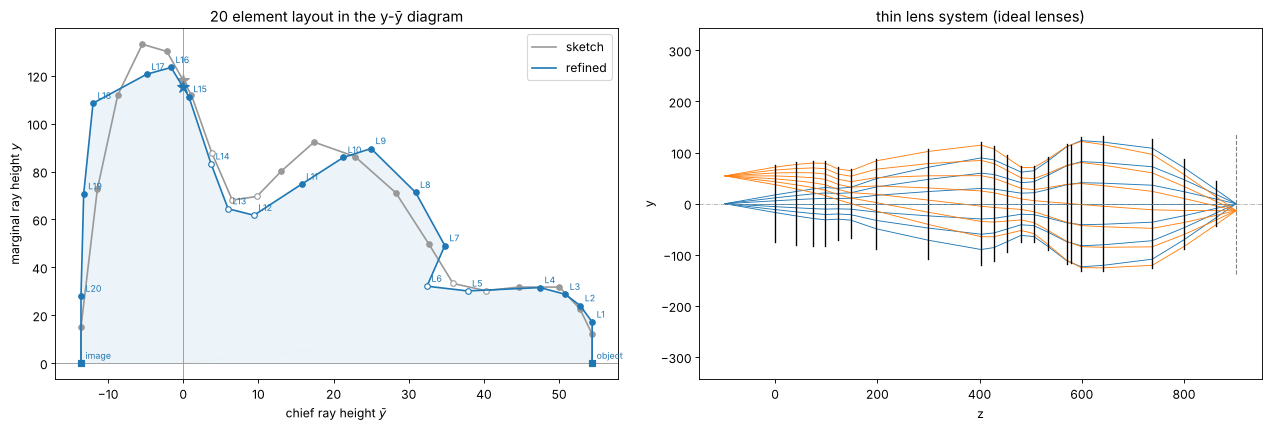

In [5]:
layout = refine(sketch, N_SIO2, min_space=25.0, spaces={-1: 40.0}, max_height=125.0, anchor=1.0)
summary(layout, "refined")

fig, axes = plt.subplots(1, 2, figsize=(16, 5.5))
sketch.plot(axes[0], color="0.6", label="sketch", annotate=False)
layout.plot(axes[0], color="C0", label="refined", areas=True)
axes[0].legend()
axes[0].set_title("20 element layout in the y-ȳ diagram")
thin = layout.to_system(WL)
thin.draw(axes[1], fields=[0.0, h])
axes[1].set_title("thin lens system (ideal lenses)")
fig.tight_layout()
pt = thin.paraxial()
print(f"thin lens system: m = {pt.magnification:.5f}, NA = {pt.na:.4f}, "
      f"length = {thin.object_distance + thin.image_z:.2f} mm, telecentric: "
      f"pupils at {pt.ep_z:.1e} and {pt.xp_z:.1e} mm")

## 4. Thick lenses with the same first order properties

`thicken()` replaces every thin lens by a fused silica singlet of the same
power, with a centre thickness (here 0.2 × the paraxial semi diameter,
15–40 mm, the last lens 30 mm) and a shape factor
$X = (c_1 + c_2)/(c_1 - c_2)$ (here equiconvex/equiconcave, $X = 0$). The
principal planes of each singlet sit where the thin lens was, so the
paraxial rays in all air spaces stay those of the layout; only the distance
between the principal planes of each lens adds to the length, which
`length=` takes out by rescaling the diagram. The diagram of the thick
system (one point per surface) goes through the same lines as the thin one:

thick start system: m = -0.25000, NA = 0.7000, length = 1000.00 mm
Seidel sums at full field: W040 = -32503, W131 = 15709, W222 = -664, W220 = -411, W311 = 725 waves


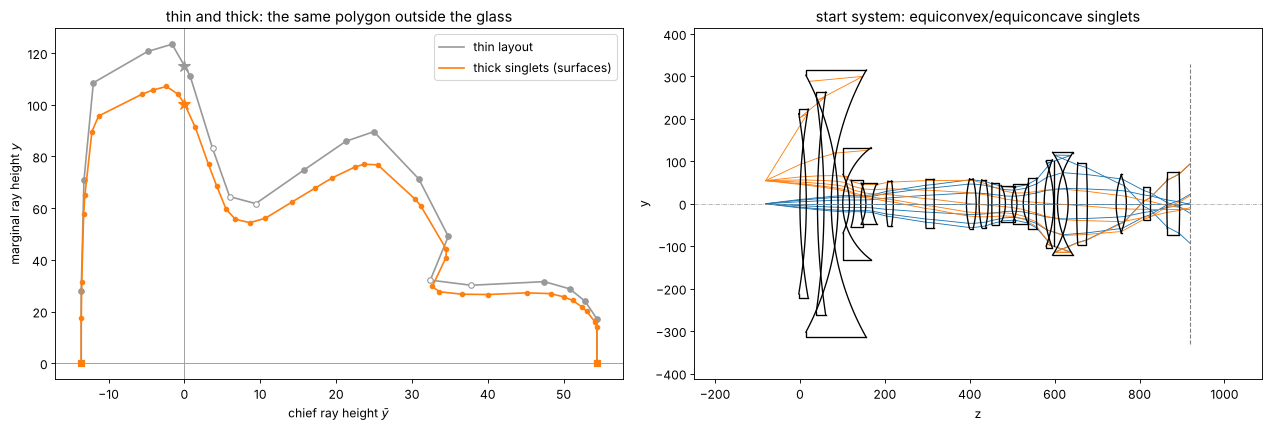

In [6]:
T = np.clip(0.2*layout.heights()[1:-1], 15, 40)
T[-1] = 30.0
start = thicken(layout, WL, rt.fused_silica, T, 0.0, length=LENGTH, check=False)
d_start = DelanoDiagram.from_system(start)
ps = start.paraxial()
print(f"thick start system: m = {ps.magnification:.5f}, NA = {ps.na:.4f}, "
      f"length = {start.object_distance + start.image_z:.2f} mm")
sd = start.seidel()
print(f"Seidel sums at full field: W040 = {sd.W040:.0f}, W131 = {sd.W131:.0f}, W222 = {sd.W222:.0f}, "
      f"W220 = {sd.W220:.0f}, W311 = {sd.W311:.0f} waves")

fig, axes = plt.subplots(1, 2, figsize=(16, 5.5))
layout.with_length(LENGTH).plot(axes[0], color="0.6", label="thin layout", annotate=False)
d_start.plot(axes[0], color="C1", label="thick singlets (surfaces)", annotate=False, signs=False)
axes[0].legend()
axes[0].set_title("thin and thick: the same polygon outside the glass")
start.draw(axes[1], fields=[0.0, h])
axes[1].set_title("start system: equiconvex/equiconcave singlets")
fig.tight_layout()

First order is now right, third order not at all: the lenses are not bent
yet, the spherical aberration alone is thousands of waves.

## 5. Correcting the aberrations with real rays

`LensOptimizer` varies all curvatures, all thicknesses (glass and air), the
object distance and the $r^4$, $r^6$ and $r^8$ coefficients of five
aspheric surfaces, about evenly spread from the reticle to the wafer (the
rear of L2, the front of L6, the rear of L10, the front of L15 next to the
stop, the rear of L19), and minimizes, by damped least squares, the
residuals of

- the transverse ray errors relative to the chief ray on four rings of the
  pupil at six fields (tolerance 0.1 µm),
- distortion against $m = -0.25$ at five fields (10 nm), image and object
  side telecentricity, the paraxial magnification,
- clearances: centre and edge thicknesses of at least 10 mm, air spaces of
  1 mm, 30 mm in front of the reticle, 8 mm working distance, checked at
  1.15 times the paraxial rim of the full beam (at NA 0.7 the real rim rays
  run up to 10 % outside the paraxial ones),
- an air space of at least 40 mm around the stop, for an iris (section 9).

The length stays 1 m (the image distance is solved) and the object side
NA (the stop size is solved). A local optimizer cannot open a lens
from scratch to NA 0.7 and the full field, the rays at the rim of the pupil
fail (they miss surfaces or are totally reflected). As in end-to-end lens
design by gradient descent, the aperture and the field are opened in
stages, here in three phases:

1. 40 %, 60 %, 80 % and 90 % of the NA and the field, telecentricity to
   1 mrad;
2. 90 % to 100 % in small steps (a large last step loses the rim rays of
   the full field), telecentricity to 0.2 mrad;
3. at full aperture and field, telecentricity and distortion of the
   **real** chief ray (`aim=True`). The ray traces of the optimizer aim at
   the paraxial entrance pupil (no ray aiming, 20 times faster), and at
   NA 0.7 the pupil aberrations put the ray that starts towards it tens of
   mrad away from the ray through the centre of the stop; `aim=True` aims
   the chief ray alone at the stop.

Two more steps follow. The specification is the NA of the real rays, and
the pupil aberrations make it differ from the paraxial one: corrected at a
paraxial NA of 0.7, the lens has a real NA of only 0.64 on axis. The
paraxial NA is therefore raised by the ratio and the lens corrected again,
three times, until the real NA is 0.70 (the paraxial one is then 0.77).
And the transverse ray errors on four rings are replaced by the wavefront
error on eight rings and ten spokes (`lo.wavefront()`): the rays of the
merit function then sample the pupil where the RMS wavefront error is
measured. On its own this trades distortion and telecentricity for the
wavefront (to 340 nm and 20 mrad); weighted ten times more, they stay
where they were.

Why `LensOptimizer` and not the classical `DampedLeastSquares` of
section 7 and notebook 58 (lens optimization) for this part? Both take
damped least squares steps, but `LensOptimizer` treats the clearances as
penalties and uses scipy's trust region method, while `DampedLeastSquares`
holds them as constraints. Far from a solution that is the wrong way round:
every step is spent on restoring violated clearances that the next stage
violates again. The constraint optimizer is the tool for the end, when the
lens is nearly corrected (section 7).

The Jacobian is analytic (`jac="analytic"`, differential ray tracing in
`pyoptics.ray_derivatives`): about 1 s instead of 17 s with finite
differences for the 96 variables, and the whole run takes about an hour
instead of several. It is reproduced in the cell below with
`RUN_FULL = True`. Otherwise only a few steps of the first stage run here
and the result is loaded from `raytrace.delano_krf_lens(aspheres=5)`, which
stores it.

In [7]:
RUN_FULL = False
STOP_SPACE = 40.0  # mm of air for the NA stop (an iris)


def stop_space(system):
    """Length of the air space that holds the stop (the stop may sit on a lens surface at one end)."""
    k, S, air = system.stop_index, system.surfaces, system._is_gap
    total, i = 0.0, k
    while i < len(S) - 1 and air(system.n[i + 1]):
        total += S[i].thickness
        i += 1
    i = k - 1
    while i >= 0 and air(system.n[i + 1]):
        total += S[i].thickness
        i -= 1
    return total


def stop_space_operand(system):
    return np.array([max(0.0, STOP_SPACE - stop_space(system))/0.01])


def real_na(system):
    """Image side NA of the real marginal ray on axis (aimed at the rim of the stop)."""
    s = system.copy()
    s.ray_aiming = True
    b = s.trace(s.rays(0.0, np.array([0.0, 0.0]), np.array([0.0, 1.0]), aim=True), clip=False)
    D = s._image_hits(b)[1]
    return np.linalg.norm(np.cross(D[1], D[0]))


def operands(telecentricity, aim, stop=True, wavefront=False, weight=1.0):
    image = (lo.wavefront(fields=(0, 0.35, 0.6, 0.8, 0.9, 1), rings=np.linspace(0.2, 1.0, 8), spokes=10,
                          tolerance=0.01) if wavefront
             else lo.ray_errors(fields=(0, 0.35, 0.6, 0.8, 0.9, 1), tolerance=1e-4))
    return [image,
            lo.distortion(M, fields=(0.25, 0.5, 0.7, 0.85, 1), aim=aim, tolerance=1e-5/weight),
            lo.image_telecentricity(tolerance=telecentricity/weight, aim=aim),
            lo.object_telecentricity(tolerance=telecentricity/weight, aim=aim),
            lo.paraxial_target("magnification", M, 1e-5),
            lo.clearances(min_center=10.0, min_edge=10.0, min_image_distance=8.0,
                          min_object_distance=30.0, margin=1.15)] + ([stop_space_operand] if stop else [])


def aspheres_of(system):
    """Rear of L2, front of L6, rear of L10, front of L15, rear of L19."""
    lens_surfaces = [i for i in range(len(system.surfaces)) if system.n[i] != system.n[i + 1]]
    return [lens_surfaces[2*k + j] for k, j in [(1, 1), (5, 0), (9, 1), (14, 0), (18, 1)]]


def optimizer(system, ops, object_na):
    return lo.LensOptimizer(system, ops, thicknesses=list(range(len(system.surfaces) - 1)),
                            object_distance=True, length=LENGTH, object_na=object_na,
                            aspheres=aspheres_of(system), asphere_orders=(4, 6, 8))


def correct(start, stop_from=1):
    """Phases 1 to 3, the real NA, the wavefront; the stop space operand from phase stop_from on."""
    system, object_na = start.copy(), NA*abs(M)
    system.ray_aiming = False  # paraxial pupil aiming is much faster
    phases = [(operands(1e-3, False, stop_from <= 1), [(a, a) for a in (0.4, 0.6, 0.8, 0.9)], 150),
              (operands(2e-4, False, stop_from <= 2), [(a, a) for a in (0.9, 0.94, 0.97, 1.0)], 200),
              (operands(2e-4, True), [(1.0, 1.0)]*3, 150)]
    for ops, stages, nfev in phases:
        system = optimizer(system, ops, object_na).run(stages=stages, max_nfev=nfev, jac="analytic").system
    for k in range(3):  # raise the paraxial NA until the real one is 0.7
        object_na *= NA/real_na(system)
        system = optimizer(system, operands(2e-4, True), object_na).run(
            stages=[(1.0, 1.0)]*2, max_nfev=150, jac="analytic").system
    return optimizer(system, operands(2e-4, True, wavefront=True, weight=10.0), object_na).run(
        stages=[(1.0, 1.0)]*2, max_nfev=150, jac="analytic").system


ASPHERES = aspheres_of(start)
t0 = time.time()
if RUN_FULL:
    design5 = correct(start)  # about an hour
else:  # a few steps of the first stage, then the stored result
    opt = optimizer(start, operands(1e-3, False), NA*abs(M))
    opt.system.ray_aiming = False
    result = opt.run(stages=[(0.4, 0.4)], max_nfev=5, jac="analytic")
    print(f"aspheres on surfaces {[i + 1 for i in ASPHERES]}; {len(opt.x)} variables, "
          f"{len(opt.residuals())} residuals; first stage at 40 % NA and field: cost "
          f"{result.stages[0][2]:.4g} after {result.stages[0][3]} evaluations ({time.time() - t0:.0f} s)")
    design5 = rt.delano_krf_lens(aspheres=5)
design5.ray_aiming = True
print(f"corrected with 5 aspheres: real NA {real_na(design5):.3f} (paraxial {design5.paraxial().na:.3f}), "
      f"RMS wavefront " + ", ".join(f"{design5.rms_opd(f*h, N=48):.2f}" for f in (0, 0.5, 1))
      + " waves at 0, 0.5, 1 of the field")

aspheres on surfaces [4, 11, 20, 29, 39]; 96 variables, 309 residuals; first stage at 40 % NA and field: cost 1.563e+09 after 5 evaluations (4 s)


corrected with 5 aspheres: real NA 0.698 (paraxial 0.769), RMS wavefront 0.22, 0.31, 0.64 waves at 0, 0.5, 1 of the field


### 5.1 Does the start matter?

A local optimizer ends in the minimum whose basin the start lies in, and
the start is the largest lever the designer has. The same pipeline was run
from four starts (each about 45 minutes; not repeated here):

- **A**, the layout of section 4 (equiconvex and equiconcave singlets);
- **B**, the same layout with every singlet bent for its own least
  spherical aberration (the classical starting rule);
- **C**, the sketch refined with less weight on staying close to it
  (`refine(..., anchor=0.3, deviation=1.0)`), a different layout with the
  same first order properties;
- **D**, Caldwell's corrected lens of section 1 (21 elements, NA 0.56),
  opened to the field and the NA of the specification: a start that is
  already corrected, at a smaller NA and field. Its apertures are those of
  NA 0.56 and are dropped (the apertures are set last, from the real ray
  footprints of the final design); so is the air space operand for the stop
  in the first two phases, where it stalled the opening of the lens.

A: 20 elements, real NA 0.698 (paraxial 0.769), RMS wavefront 0.222 / 0.313 / 0.642 waves (field 0 / 0.5 / 1), stop air space 98 mm
D: 21 elements, real NA 0.702 (paraxial 0.719), RMS wavefront 0.109 / 0.162 / 0.244 waves (field 0 / 0.5 / 1), stop air space 55 mm
start C: largest semi diameter 127 mm (layout of section 3: 125 mm)


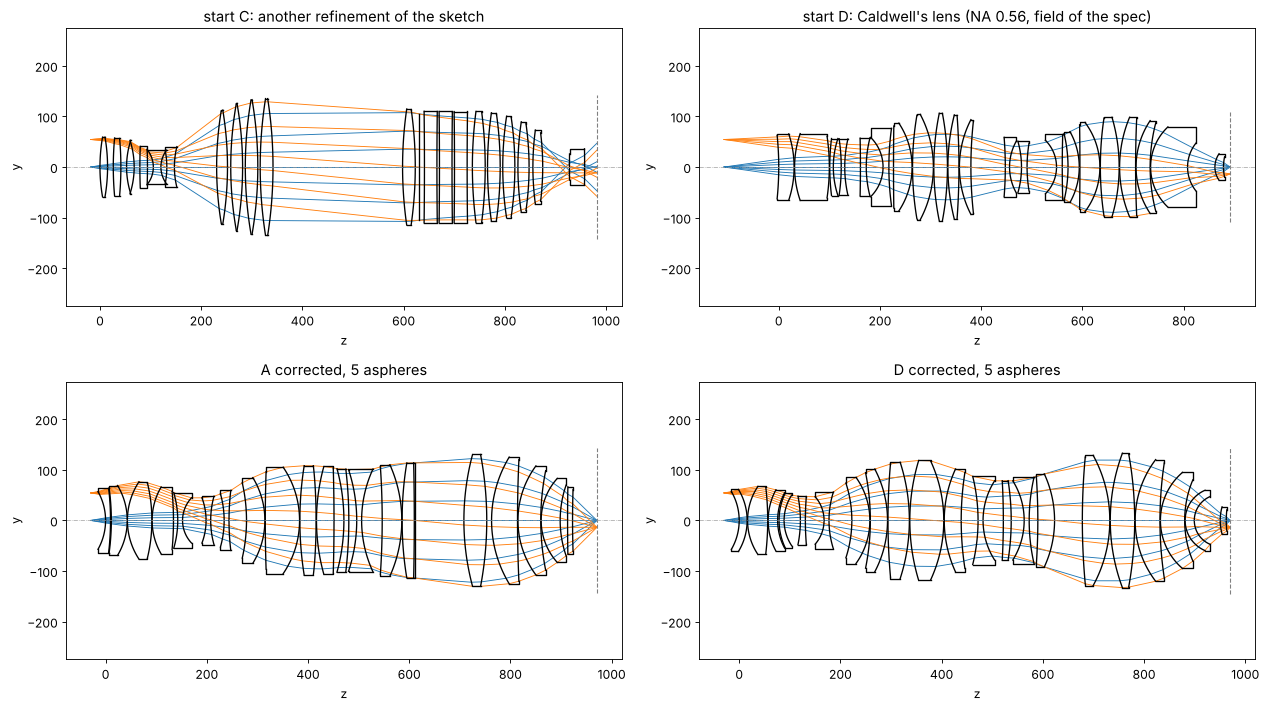

In [8]:
layout_c = refine(sketch, N_SIO2, min_space=25.0, spaces={-1: 40.0}, max_height=125.0, anchor=0.3,
                  deviation=1.0)
T_c = np.clip(0.2*layout_c.heights()[1:-1], 15, 40)
T_c[-1] = 30.0
start_c = thicken(layout_c, WL, rt.fused_silica, T_c, 0.0, length=LENGTH, check=False)
start_d = rt.caldwell_krf_lens()
start_d.max_field = h
caldwell5 = rt.delano_krf_lens(start="caldwell", aspheres=5)

fig, axes = plt.subplots(2, 2, figsize=(16, 9))
for ax, s, title in [(axes[0, 0], start_c, "start C: another refinement of the sketch"),
                     (axes[0, 1], start_d, "start D: Caldwell's lens (NA 0.56, field of the spec)"),
                     (axes[1, 0], design5, "A corrected, 5 aspheres"),
                     (axes[1, 1], caldwell5, "D corrected, 5 aspheres")]:
    s.draw(ax, fields=[0.0, h])
    ax.set_title(title)
fig.tight_layout()
for name, s in [("A", design5), ("D", caldwell5)]:
    s.ray_aiming = True
    print(f"{name}: {len(s.elements())} elements, real NA {real_na(s):.3f} (paraxial {s.paraxial().na:.3f}), "
          f"RMS wavefront {s.rms_opd(0.0, N=48):.3f} / {s.rms_opd(0.5*h, N=48):.3f} / {s.rms_opd(h, N=48):.3f} "
          f"waves (field 0 / 0.5 / 1), stop air space {stop_space(s):.0f} mm")
print(f"start C: largest semi diameter {np.max(layout_c.heights()):.0f} mm (layout of section 3: "
      f"{np.max(layout.heights()):.0f} mm)")

With the transverse ray errors as the merit function (phases 1 to 3, at
the paraxial NA 0.7, before the steps for the real NA and the wavefront):

| start | cost at the start (40 % / 100 % NA and field) | cost after phase 3 | RMS wavefront [waves] |
|---|---|---|---|
| A, layout of section 4 | 4.6e10 / 6.1e12 | 561 | 0.08–0.26 |
| B, singlets bent for least spherical aberration | 5.6e11 / 1.2e12 | 2.2e6 | 4–13 (failed) |
| C, another refinement of the sketch | 1.3e10 / 9.9e12 | 2.1e6 | 5–15 (failed) |
| D, Caldwell's lens | 3.8e7 / 3.9e7 | 795 | 0.14–0.19 |

- **B and C fail.** Both lose the rim rays while the aperture opens and
  never recover: the cost stays in the millions. Bending each singlet for
  its own minimum of spherical aberration is a rule for lenses that
  correct alone; here the lenses correct each other, and the bending puts
  the start in another basin. Layout C, with less weight on the sketch,
  shifts power between the groups, and that basin is no better.
- **D starts five orders of magnitude lower** (it is a corrected lens,
  only at a smaller NA and field) and ends at a cost close to that of A.
  Opening a corrected design is a start that a designer would choose in
  practice.
- **At the real NA of 0.7 the starts separate.** Corrected at the paraxial
  NA 0.7, A has a real NA of only 0.64 and D of 0.71. Raising A to the real
  NA 0.7 costs it a factor of two to four in the wavefront error (0.22 to
  0.64 waves after the wavefront phase); D, at 0.11 to 0.24 waves, copes
  much better.

Neither is diffraction limited yet (the Maréchal limit is 0.07 waves).
Five aspheres are not many for NA 0.7: where should more go?

## 6. Where should more aspheres go?

The five aspheres of section 5 were placed by hand, about evenly from the
reticle to the wafer. The classical rule is the **pupil closeness** of a
surface, $|y|/(|y| + |\bar y|)$ (notebook 58, lens optimization): an
asphere next to the stop, where all field points share the same footprint,
corrects aperture aberrations (spherical aberration and its higher orders)
for the whole field at once; an asphere near the reticle or the wafer,
where the beams of different field points are separated, acts on each
field point separately and corrects field aberrations (distortion,
telecentricity, astigmatism and field curvature of high order).

The sensitivities give a number for each surface.
`DampedLeastSquares.predicted_gain()` adds the $r^4$, $r^6$ and $r^8$ terms
of an asphere on one surface to the variables, solves the linearized step
with the active constraints held where they are, and returns how much
lower the merit function would get than with the current variables alone:
the part of the residuals that the new columns of the Jacobian reach and
the old ones do not. A term that does what a curvature already does
gains nothing. The merit function is that of the wavefront phase, for
`DampedLeastSquares`: the same variables, the wavefront, distortion and
telecentricity as operands, the clearances as constraints (section 7).

A ranking of single surfaces is not yet a choice of five: two aspheres on
neighbouring surfaces partly do the same. The cell adds the best surface to
the variables and ranks again, five times (greedily).

merit function 7.651e+05, of the linearized step with the 5 aspheres 7.106e+05, with 5 more 4.983e+05 (36 s)
largest predicted gains of one more asphere: surface 1 9.1 %, surface 3 8.8 %, surface 2 7.0 %, surface 16 4.9 %, surface 5 4.8 %, surface 6 4.4 %
greedy choice: surface 1, surface 16, surface 2, surface 12, surface 6


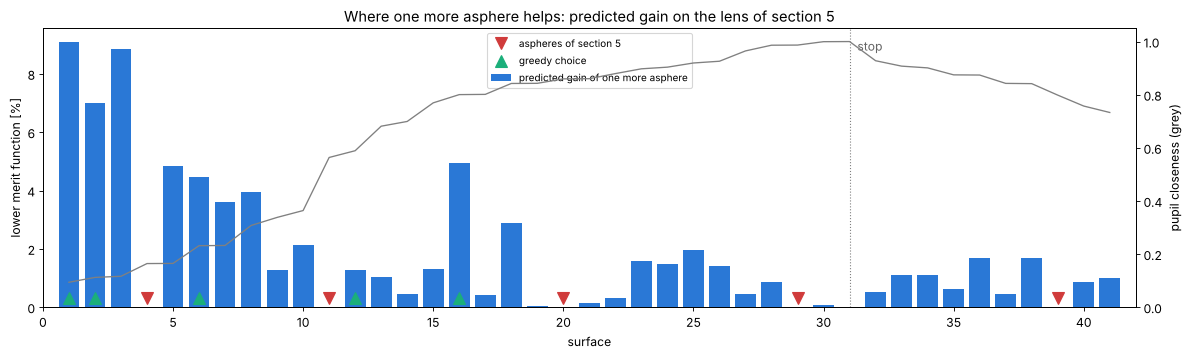

In [9]:
def dls_problem(system, aspheres, object_na, edge_heights=None):
    """The wavefront phase for DampedLeastSquares: all curvatures and thicknesses, the object
    distance and the aspheric terms as variables; wavefront, distortion and telecentricity as
    operands; clearances (edges at edge_heights, default 1.05 times the paraxial rim) as
    constraints; solves for the length and the object side NA."""
    system = system.copy()
    system.ray_aiming = False
    p = system.paraxial()
    rim = np.abs(p.marginal[:, 0]) + np.abs(p.chief[:, 0])
    n_s = len(system.surfaces)
    variables = (lo.curvatures(system) + [lo.Thickness(i) for i in range(n_s - 1)]
                 + [lo.ObjectDistance()] + [lo.Aspheric(i, k, rim[i]) for i in aspheres for k in (4, 6, 8)])
    ops = operands(2e-4, True, stop=False, wavefront=True, weight=10.0)[:4]

    def edge(i):
        return lo.edge_thickness(i) if edge_heights is None else lo.edge_thickness(i, height=edge_heights[i])

    els = system.elements()
    cons = [lo.Constraint(lo.paraxial_value("magnification"), M, M, 1e-6, "magnification")]
    for k, (a, b) in enumerate(els):
        cons += [lo.Constraint(lo.center_thickness(a), lower=10.0, tolerance=0.01, name=f"centre L{k + 1}"),
                 lo.Constraint(edge(a), lower=10.0, tolerance=0.01, name=f"edge L{k + 1}")]
    for (a0, b0), (a1, b1) in zip(els[:-1], els[1:]):
        for i in range(b0, a1):
            cons += [lo.Constraint(lo.center_thickness(i), lower=1.0, tolerance=0.01, name=f"air {i + 1}"),
                     lo.Constraint(edge(i), lower=1.0, tolerance=0.01, name=f"air edge {i + 1}")]
    cons += [lo.Constraint(lambda s: s.object_distance, lower=30.0, tolerance=0.01, name="object distance"),
             lo.Constraint(lo.center_thickness(n_s - 1), lower=8.0, tolerance=0.01, name="working distance"),
             lo.Constraint(stop_space, lower=STOP_SPACE, tolerance=0.01, name="stop space")]
    return lo.DampedLeastSquares(system, variables, ops, cons,
                                 solves=[lo.solve_length(LENGTH), lo.solve_object_na(object_na)],
                                 jac="analytic")


t0 = time.time()
object_na5 = design5.paraxial().na*abs(M)
dls5 = dls_problem(design5, ASPHERES, object_na5)
p5 = dls5.system.paraxial()
rim5 = np.abs(p5.marginal[:, 0]) + np.abs(p5.chief[:, 0])
lens_surfaces = [i for i in range(len(design5.surfaces)) if design5.n[i] != design5.n[i + 1]]
closeness = dls5.system.pupil_closeness()
chosen, dls_g = [], dls5
for k in range(5):
    candidates = {i: [lo.Aspheric(i, j, rim5[i]) for j in (4, 6, 8)]
                  for i in lens_surfaces if i not in ASPHERES + chosen}
    gains, base = dls_g.predicted_gain(candidates, damping=1e-6)
    if k == 0:
        gains_1, base_1 = gains, base
    best = max(gains, key=gains.get)
    chosen.append(best)
    dls_g = lo.DampedLeastSquares(dls_g.system, dls_g.variables + candidates[best], dls_g.operands,
                                  dls_g.constraints, solves=dls_g.solves, jac="analytic")
base_10 = dls_g.predicted_gain({"none": []}, damping=1e-6)[1]
print(f"merit function {dls5.merit():.4g}, of the linearized step with the 5 aspheres {base_1:.4g}, "
      f"with 5 more {base_10:.4g} ({time.time() - t0:.0f} s)")
order = sorted(gains_1, key=lambda i: -gains_1[i])
print("largest predicted gains of one more asphere:",
      ", ".join(f"surface {i + 1} {100*gains_1[i]/base_1:.1f} %" for i in order[:6]))
print("greedy choice:", ", ".join(f"surface {i + 1}" for i in chosen))

fig, ax = plt.subplots(figsize=(15, 4.6))
surf = np.array(sorted(gains_1))
ax.bar(surf + 1, [100*gains_1[i]/base_1 for i in surf], color="#2a78d6", label="predicted gain of one more asphere")
ax.plot([i + 1 for i in ASPHERES], [0.3]*len(ASPHERES), "v", color="#d03b3b", ms=10, label="aspheres of section 5")
ax.plot([i + 1 for i in chosen], [0.3]*len(chosen), "^", color="#1baf7a", ms=10, label="greedy choice")
ax.set_xlabel("surface")
ax.set_ylabel("lower merit function [%]")
ax.set_xlim(0, len(design5.surfaces) + 1)
ax2 = ax.twinx()
ax2.plot(np.arange(1, len(closeness) + 1), closeness, "-", color="0.5", lw=1.2)
ax2.set_ylim(0, 1.05)
ax2.set_ylabel("pupil closeness (grey)")
ax2.grid(False)
ax.axvline(design5.stop_index + 1, color="0.5", ls=":", lw=1)
ax.text(design5.stop_index + 1.3, ax.get_ylim()[1]*0.92, "stop", color="0.4")
ax.legend(loc="upper center", fontsize=9)
ax.set_title("Where one more asphere helps: predicted gain on the lens of section 5")
fig.tight_layout()

The gain is largest at the reticle (surfaces 1 to 3, 7 to 9 % each),
next in the first group and at the front of the second bulge (surfaces 5
to 8 and 16, 4 to 5 %), and small around the stop (at most 2 %), where the
asphere on surface 29 already sits. That is the pupil closeness rule seen
from the other side: what section 5 left is mostly field dependent (the
wavefront error grows from 0.22 waves in the centre of the field to 0.64
at its edge), and field aberrations are corrected where the beams of the
field points are apart. The greedy choice takes surfaces 1, 16, 2, 12
and 6 and predicts a merit function 30 % lower. The same ranking on the
lens from Caldwell's start picks surfaces 1, 42, 41, 2 and 8: the first
and the last surfaces, at both ends of the lens.

## 7. Polishing with `DampedLeastSquares`: more aspheres, clearances as constraints and their price

`LensOptimizer` treats the clearances as penalties: a lens that is 10 µm
too thin costs as much merit as a ray that misses by 0.1 µm, and the
optimizer trades the two; the lens of section 5 has lenses of 9.1 mm and
air spaces of 0.3 mm. `lens_optimization.DampedLeastSquares` (the
classical lens design optimizer of notebook 58, lens optimization) holds
them as **constraints** with Lagrange multipliers instead: every step keeps
the linearized active constraints exactly, and at the end the multiplier of
each active constraint says what it costs, $\partial\Phi/\partial b = -2\mu$
for a bound $b$ (merit per mm of clearance). The variables are those of
section 5 and the five aspheres of section 6; the solves keep the length
and the object side NA; the operands are those of the wavefront phase; the
magnification, 10 mm centre and edge thickness of every lens, 1 mm air
spaces on axis and at the rim, 30 mm object distance, 8 mm working distance
and the 40 mm air space of the stop are constraints. The edges are checked
at the real ray footprints (2 % added), not at the paraxial rim.

The cell runs the first iterations: with the five aspheres of section 5
until the constraints hold, then with all ten. The polish that gave the
stored design (`raytrace.delano_krf_lens()`) went on for about 1200
iterations in rounds of 100 to 300 (about 2 s each), the paraxial NA
adjusted between rounds to keep the real one at 0.7, the edge heights
taken again from the footprints.

In [10]:
def footprints(system, fields=(0.0, 0.25, 0.5, 0.75, 1.0, -1.0), n=31):
    """Largest radius of the real rays of the full NA on every surface (a grid and the rim)."""
    s = system.copy()
    s.ray_aiming = True
    for i, x in enumerate(s.surfaces):
        if i != s.stop_index:
            x.semi_diameter = None
    px, py = np.meshgrid(np.linspace(-1, 1, n), np.linspace(-1, 1, n))
    inside = px**2 + py**2 <= 1
    phi = np.linspace(0, 2*np.pi, 360, endpoint=False)
    px, py = np.concatenate([px[inside], np.cos(phi)]), np.concatenate([py[inside], np.sin(phi)])
    r = np.zeros(len(s.surfaces))
    for f in fields:
        P = np.asarray(s.trace(s.rays(f*h, px, py, aim=True), clip=False).points)
        r = np.maximum(r, np.nanmax(np.hypot(P[..., 0], P[..., 1])[1:len(s.surfaces) + 1], axis=1))
    return r


ASPHERES_10 = sorted(ASPHERES + chosen)
fp = footprints(design5)
heights = [1.02*max(fp[i], fp[i + 1]) for i in range(len(fp) - 1)] + [0.0]
t0 = time.time()
dls = dls_problem(design5, ASPHERES, object_na5, heights)
print(f"{len(dls.variables)} variables, {len(dls.residuals())} residuals, {len(dls.constraints)} constraints; "
      f"largest clearance violation of the lens of section 5 {np.max(np.abs(dls.constraint_values()[1]))*0.01:.2f} mm")
res_5 = dls.run(max_iterations=15, verbose=True)
dls = dls_problem(res_5.system, ASPHERES_10, object_na5, heights)
res_10 = dls.run(max_iterations=15, verbose=True)
print(f"{time.time() - t0:.0f} s")
design = rt.delano_krf_lens()  # the stored result of the whole polish
design.ray_aiming = True
for f in (0.0, 0.5, 1.0):
    print(f"field {f:.1f}: RMS wavefront {design5.rms_opd(f*h, N=48):.3f} (section 5) -> "
          f"{res_10.system.rms_opd(f*h, N=48):.3f} (after 30 iterations here) -> "
          f"{design.rms_opd(f*h, N=48):.3f} waves (stored)")

96 variables, 305 residuals, 84 constraints; largest clearance violation of the lens of section 5 0.91 mm


  0  merit 765111  damping 0.01  violation 91.4


  1  merit 3.54496e+08  damping 0.01  violation 35.8


  2  merit 8.06237e+07  damping 0.00333  violation 0.355


  3  merit 1.95428e+07  damping 0.00111  violation 0.379


  4  merit 6.8025e+06  damping 0.00037  violation 0.819


... (23 outputs left out)

 13  merit 509825  damping 3.67e-06  violation 0.0856


 14  merit 498669  damping 3.57e-06  violation 0.0746
42 s


field 0.0: RMS wavefront 0.222 (section 5) -> 0.170 (after 30 iterations here) -> 0.032 waves (stored)
field 0.5: RMS wavefront 0.313 (section 5) -> 0.267 (after 30 iterations here) -> 0.046 waves (stored)


field 1.0: RMS wavefront 0.642 (section 5) -> 0.629 (after 30 iterations here) -> 0.075 waves (stored)


The first step restores the clearances (the penalties had left them
violated by up to 0.9 mm) and the merit function jumps by a factor of
500; the following steps bring it back, with a damping close to zero
(Gauss-Newton steps). With all ten aspheres it soon falls below the start
and keeps falling, slowly, by a few per cent per step: 30 iterations here
lower the wavefront error in the centre of the field from 0.22 to 0.17
waves. The whole polish (about 1200 iterations, an hour and a quarter)
reaches 0.03 to 0.08 waves over the field, the lens from Caldwell's start
(the same procedure) 0.01 to 0.05: both are diffraction limited, a factor
of five to ten better than with five aspheres.

Does it matter when the five extra aspheres come in? Run through the whole
pipeline of section 5 with all ten aspheres from the first stage (about
1.5 hours each, not repeated here), the lens from Caldwell's start reaches
0.05 to 0.14 waves (0.11 to 0.24 with five) and, after 300 iterations of
the same polish, 0.02 to 0.05 waves: as good as adding them late. The lens
from the Delano layout ends in a much worse minimum, 0.48 to 1.5 waves,
from which the polish cannot move it at all (no step lowers the merit
function). The extra aspheres change the path through the early, wide open
stages, and for the drawn layout that path is a dead end. Adding variables
late, to a lens that already sits in a good basin, is the safer order.

merit 89380 -> 89380 after 3 iterations; 9 active clearances
magnification: 2|μ| = 2.24e+09 per unit of m, i.e. 22409.8 merit for a change of 1e-5


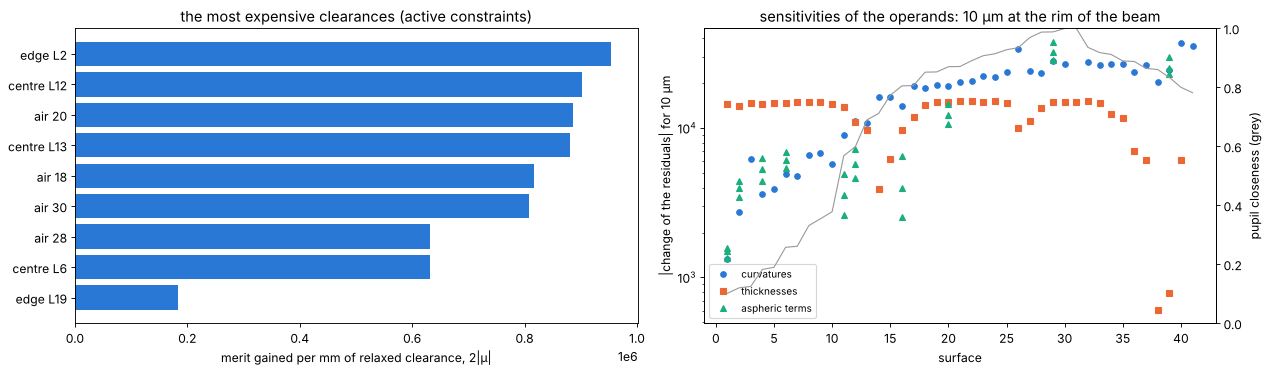

In [11]:
# the prices at the stored design: a few more iterations there give the multipliers
heights_fin = [1.02*max(a, b) for a, b in zip(footprints(design)[:-1], footprints(design)[1:])] + [0.0]
dls_fin = dls_problem(design, ASPHERES_10, design.paraxial().na*abs(M), heights_fin)
dls_vars = dls_fin.variables
res_dls = dls_fin.run(max_iterations=3)
polished = res_dls.system
polished.ray_aiming = True
n_s = len(design.surfaces)
mu = {k: v for k, v in res_dls.multipliers.items() if k != "magnification"}
names_sorted = sorted(mu, key=lambda k: -abs(mu[k]))[:16]
fig, axes = plt.subplots(1, 2, figsize=(16, 4.8), gridspec_kw={"width_ratios": [1.1, 1]})
ax = axes[0]
ax.barh(range(len(names_sorted)), [2*abs(mu[k]) for k in names_sorted], color="#2a78d6")
ax.set_yticks(range(len(names_sorted)), names_sorted)
ax.invert_yaxis()
ax.set_xlabel("merit gained per mm of relaxed clearance, 2|μ|")
ax.set_title("the most expensive clearances (active constraints)")

# sensitivities: change of the residual vector for 10 µm of change at the rim of the beam
# (a sag of 10 µm for curvatures and aspheric terms, 10 µm of thickness)
rim_p = np.abs(polished.paraxial().marginal[:, 0]) + np.abs(polished.paraxial().chief[:, 0])
step = np.array([2*0.01/rim_p[v.surface]**2 if isinstance(v, lo.Curvature) else 0.01
                 for v in dls_vars])
norm = np.linalg.norm(dls_fin.jacobian()[0]*step, axis=0)
ax = axes[1]
for kind, mk, col in [(lo.Curvature, "o", "#2a78d6"), (lo.Thickness, "s", "#eb6834"),
                      (lo.Aspheric, "^", "#1baf7a")]:
    idx = [j for j, v in enumerate(dls_vars) if isinstance(v, kind)]
    ax.semilogy([dls_vars[j].surface + 1 for j in idx], norm[idx], mk, color=col, ms=5,
                label={lo.Curvature: "curvatures", lo.Thickness: "thicknesses",
                       lo.Aspheric: "aspheric terms"}[kind])
ax2 = ax.twinx()
ax2.plot(np.arange(1, n_s + 1), polished.pupil_closeness(), "-", color="0.6", lw=1)
ax2.set_ylabel("pupil closeness (grey)")
ax2.set_ylim(0, 1)
ax2.grid(False)
ax.set_xlabel("surface")
ax.set_ylabel("|change of the residuals| for 10 µm")
ax.set_title("sensitivities of the operands: 10 µm at the rim of the beam")
ax.legend(fontsize=9, loc="lower left")
fig.tight_layout()
print(f"merit {dls_fin.merit():.0f} -> {res_dls.merit:.0f} after 3 iterations; {len(mu)} active clearances")
print(f"magnification: 2|μ| = {2*abs(res_dls.multipliers.get('magnification', 0.0)):.3g} per unit of m, "
      f"i.e. {2e-5*abs(res_dls.multipliers.get('magnification', 0.0)):.1f} merit for a change of 1e-5")

At the polished lens nine clearances are active. The most expensive are
the edge of L2, the centres of L12 and L13 (the thin negative lenses of the
first group) and the air spaces behind surfaces 18, 20, 28 and 30, all
within a factor of two of each other; a designer who wants to relieve one
of them, a thicker lens or a wider gap, knows which. The magnification is
by far the most expensive constraint: a change of $10^{-5}$ would buy a
quarter of the merit function, which is what the specification forbids.

The sensitivities (the columns of the Jacobian, which are the tolerance
sensitivities of `raytrace.System`), here for the same 10 µm of change at
the rim of the beam, show which variables act on the operands most. A
thickness moves everything behind it and acts about equally everywhere
(less in front of the wafer). A sag change of a curvature or an asphere
acts more the closer the surface is to the stop: near the reticle the
curvatures act a quarter to a half as much as the thicknesses, near the
stop twice as much. The aspheres on surfaces 1 and 2 are the weakest
variables of all, those next to the stop (29) and in front of the wafer
(39) about sixty times stronger. Weak is not useless: section 6 ranked
surface 1 first. What an asphere is worth depends on what nothing else can
do at its place, not on how strongly it acts.

## 8. The corrected lens

design: m = -0.25000, real NA 0.701 on axis (paraxial 0.775), length = 1000.000 mm, working distance 62.7 mm, object distance 31.6 mm, 589 mm of glass, largest clear semi diameter 140 mm, aspheres on surfaces [1, 2, 4, 6, 11, 12, 16, 20, 29, 39]
glass: thinnest centre 10.00 mm, thinnest edge 10.42 mm; air: closest 1.00 mm on axis, 1.51 mm at the clear aperture; stop air space 100 mm


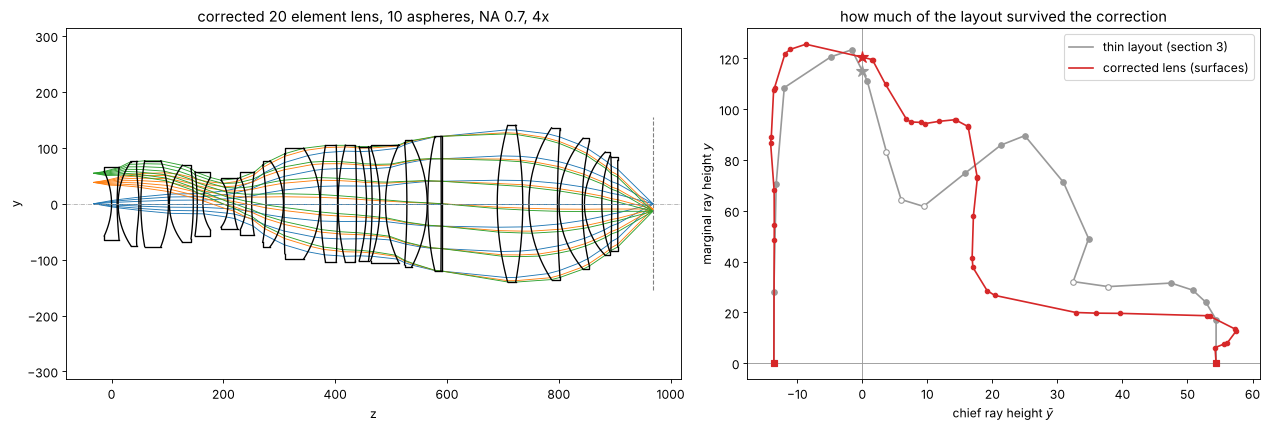

In [12]:
pd = design.paraxial()
d_design = DelanoDiagram.from_system(design)
S = design.surfaces
glass = [i for i in range(len(S)) if not design._is_gap(design.n[i + 1])]
print(f"design: m = {pd.magnification:.5f}, real NA {real_na(design):.3f} on axis (paraxial {pd.na:.3f}), "
      f"length = {design.object_distance + design.image_z:.3f} mm, working distance "
      f"{S[-1].thickness:.1f} mm, object distance {design.object_distance:.1f} mm, "
      f"{sum(S[i].thickness for i in glass):.0f} mm of glass, largest clear semi diameter "
      f"{max(s.semi_diameter for s in S):.0f} mm, aspheres on surfaces {[i + 1 for i in ASPHERES_10]}")
# clearances at the clear apertures (set last, from the real ray footprints of the full field and NA)
edge = np.array([S[i].thickness + S[i + 1].sag(np.array([r*r]))[0] - S[i].sag(np.array([r*r]))[0]
                 for i, r in enumerate(max(a.semi_diameter, b.semi_diameter) for a, b in zip(S[:-1], S[1:]))])
air = np.array([design._is_gap(design.n[i + 1]) for i in range(len(S) - 1)])
centre = np.array([s.thickness for s in S[:-1]])
print(f"glass: thinnest centre {centre[~air].min():.2f} mm, thinnest edge {edge[~air].min():.2f} mm; air: "
      f"closest {centre[air].min():.2f} mm on axis, {edge[air].min():.2f} mm at the clear aperture; "
      f"stop air space {stop_space(design):.0f} mm")

fig, axes = plt.subplots(1, 2, figsize=(16, 5.5), gridspec_kw={"width_ratios": [1.2, 1]})
design.draw(axes[0], fields=[0.0, 0.7*h, h])
axes[0].set_title("corrected 20 element lens, 10 aspheres, NA 0.7, 4x")
layout.plot(axes[1], color="0.6", label="thin layout (section 3)", annotate=False)
d_design.plot(axes[1], color="C3", label="corrected lens (surfaces)", annotate=False, signs=False)
axes[1].legend()
axes[1].set_title("how much of the layout survived the correction")
fig.tight_layout()

r =  0.00 mm: RMS wavefront 0.032 waves (D: 0.012), spot 0.36 µm rms, distortion    +0 nm, chief ray  +0.0 /  +0.0 mrad (object / image)
r =  1.36 mm: RMS wavefront 0.033 waves (D: 0.012), spot 0.37 µm rms, distortion    +1 nm, chief ray  -0.5 /  -0.1 mrad (object / image)
r =  2.72 mm: RMS wavefront 0.038 waves (D: 0.017), spot 0.38 µm rms, distortion    +5 nm, chief ray  -0.9 /  -0.2 mrad (object / image)
r =  4.08 mm: RMS wavefront 0.044 waves (D: 0.022), spot 0.40 µm rms, distortion   +13 nm, chief ray  -1.1 /  -0.2 mrad (object / image)
r =  5.44 mm: RMS wavefront 0.049 waves (D: 0.025), spot 0.42 µm rms, distortion   +16 nm, chief ray  -1.1 /  -0.3 mrad (object / image)
r =  6.80 mm: RMS wavefront 0.046 waves (D: 0.027), spot 0.42 µm rms, distortion   +10 nm, chief ray  -0.7 /  -0.3 mrad (object / image)
r =  8.16 mm: RMS wavefront 0.039 waves (D: 0.027), spot 0.40 µm rms, distortion    -5 nm, chief ray  -0.2 /  -0.3 mrad (object / image)
r =  9.52 mm: RMS wavefront 0.043 waves (

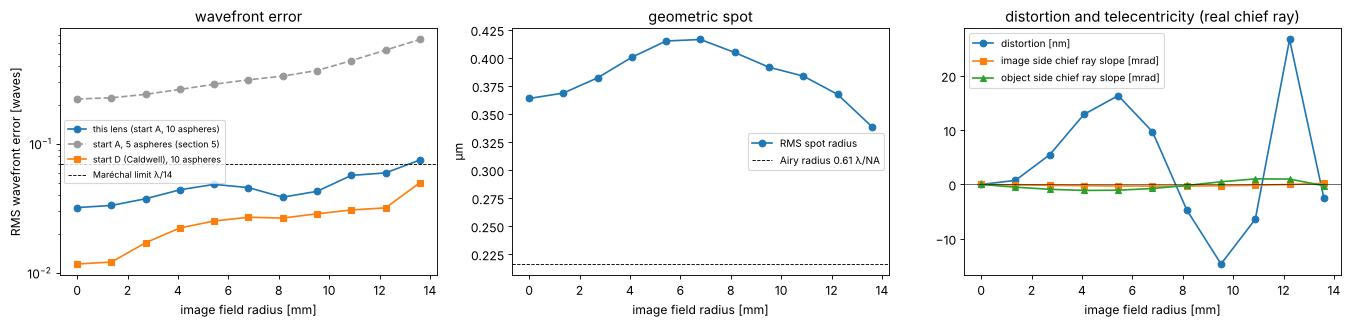

In [13]:
caldwell = rt.delano_krf_lens(start="caldwell")
caldwell.ray_aiming = True
fields = np.linspace(0, 1, 11)
rms = np.array([design.rms_opd(field=f*h, N=48) for f in fields])
rms_c = np.array([caldwell.rms_opd(field=f*h, N=48) for f in fields])
rms_5 = np.array([design5.rms_opd(field=f*h, N=48) for f in fields])
spots = [design.spot_diagram(f*h, N=21) for f in fields]
dist, tele, tele_obj = [], [], []
for f in fields:
    rays = design.rays(f*h, 0.0, 0.0)  # the chief ray, aimed at the centre of the stop
    d0 = np.reshape(rays.directions, (-1, 3))[0]
    I, D = design._image_hits(design.trace(rays, clip=False))
    dist.append((I[0, 1] - M*f*h)*1e6)
    tele.append(D[0, 1]/D[0, 2]*1e3)
    tele_obj.append(d0[1]/d0[2]*1e3)

fig, axes = plt.subplots(1, 3, figsize=(17, 4.2))
r_img = fields*R_FIELD
axes[0].semilogy(r_img, rms, "o-", label="this lens (start A, 10 aspheres)")
axes[0].semilogy(r_img, rms_5, "o--", color="0.6", label="start A, 5 aspheres (section 5)")
axes[0].semilogy(r_img, rms_c, "s-", label="start D (Caldwell), 10 aspheres")
axes[0].axhline(0.07, color="k", ls="--", lw=0.8, label="Maréchal limit λ/14")
axes[0].set_xlabel("image field radius [mm]"); axes[0].set_ylabel("RMS wavefront error [waves]")
axes[0].legend(fontsize=8); axes[0].set_title("wavefront error")
axes[1].plot(r_img, [s.rms*1e3 for s in spots], "o-", label="RMS spot radius")
axes[1].axhline(0.61*WL*1e3/NA, color="k", ls="--", lw=0.8, label="Airy radius 0.61 λ/NA")
axes[1].set_xlabel("image field radius [mm]"); axes[1].set_ylabel("µm"); axes[1].legend(fontsize=9)
axes[1].set_title("geometric spot")
axes[2].plot(r_img, dist, "o-", label="distortion [nm]")
axes[2].plot(r_img, tele, "s-", label="image side chief ray slope [mrad]")
axes[2].plot(r_img, tele_obj, "^-", label="object side chief ray slope [mrad]")
axes[2].axhline(0, color="k", lw=0.5); axes[2].set_xlabel("image field radius [mm]")
axes[2].legend(fontsize=9); axes[2].set_title("distortion and telecentricity (real chief ray)")
fig.tight_layout()
for f, w, wc, s, dd, t, to in zip(fields, rms, rms_c, spots, dist, tele, tele_obj):
    print(f"r = {f*R_FIELD:5.2f} mm: RMS wavefront {w:.3f} waves (D: {wc:.3f}), spot {s.rms*1e3:.2f} µm rms, "
          f"distortion {dd:+5.0f} nm, chief ray {to:+5.1f} / {t:+5.1f} mrad (object / image)")

The lens from the Delano layout is corrected to 0.03 to 0.075 waves RMS
over the field, at or below the Maréchal limit everywhere (the lens from
Caldwell's start: 0.01 to 0.05), with distortions below 30 nm and a real
chief ray that leaves the reticle at less than 1.1 mrad and meets the wafer
at less than 0.3 mrad: telecentric on both sides. The geometric spots
(0.34 to 0.42 µm RMS) are larger than the Airy radius; at this level of
correction the geometric spot says little, the image is formed by
diffraction. Distortion is only controlled at the sampled fields (0.25,
0.5, 0.7, 0.85 and 1 of the field): it peaks at 27 nm between the last two.

The diagram of the corrected lens keeps the telecentric ends and the
large bulge around the stop, but not the two waists of the layout: the
correction made the first group one long, slim waist (marginal ray heights
of about 20 in the units of the plot instead of 30 to 90) and removed the
second, so that the beam grows from the first waist to the stop in one
sweep. The optimizer spread the negative power for the Petzval sum over
the first group.

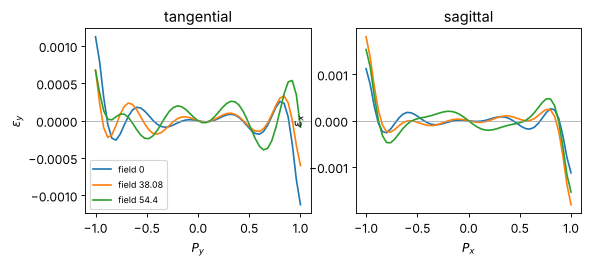

In [14]:
axes = design.plot_ray_fan(fields=[0.0, 0.7*h, h])

### The wavefront in Zernike polynomials

`System.zernike()` fits Fringe Zernike polynomials (peak value 1 on the rim
of the pupil) to the OPD map against the reference sphere around the chief
ray image point. Z1 (piston) carries no information; Z2/Z3 (tilt) is the
shift of the diffraction focus against the chief ray, Z4 a defocus, the
rest the aberrations proper. In the field centre only rotationally
symmetric terms remain (Z4, Z9, Z16, Z25: defocus and spherical aberration
of 4th, 6th and 8th order); at the edge of the field (a y field, mirror
symmetric in x) the terms even in x join them: cos mφ for even m
(astigmatism, tetrafoil) and sin mφ for odd m (y tilt, y coma, trefoil).

field centre: RMS of Z2-Z25 0.033 waves, of the whole OPD 0.033 waves; largest (RMS) Z25 -29 mλ, Z4 -12 mλ, Z16 -10 mλ, Z9 -1 mλ
field edge (r = 13.6 mm): RMS of Z2-Z25 0.089 waves, of the whole OPD 0.091 waves; largest (RMS) Z3 +51 mλ, Z21 -37 mλ, Z5 -29 mλ, Z4 +28 mλ


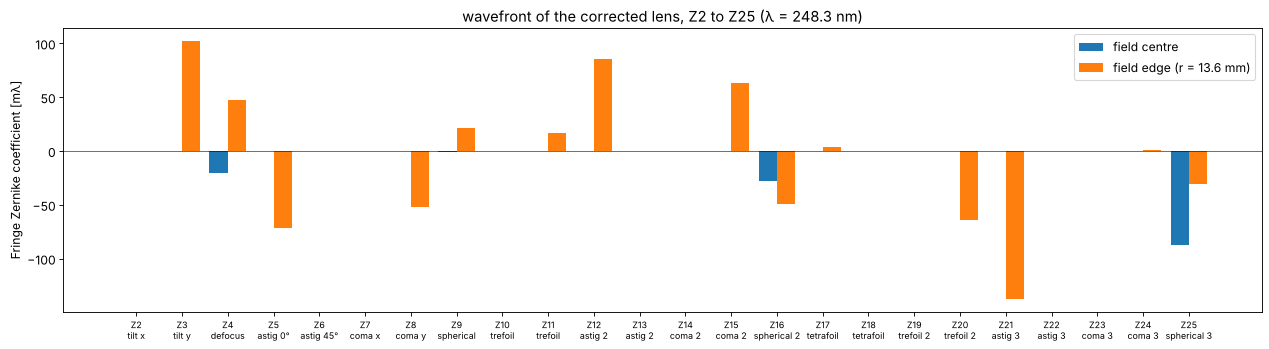

In [15]:
from pyoptics.bases import fringe_to_n_m

J = np.arange(2, 26)
names = {2: "tilt x", 3: "tilt y", 4: "defocus", 5: "astig 0°", 6: "astig 45°", 7: "coma x",
         8: "coma y", 9: "spherical", 10: "trefoil", 11: "trefoil", 12: "astig 2", 13: "astig 2",
         14: "coma 2", 15: "coma 2", 16: "spherical 2", 17: "tetrafoil", 18: "tetrafoil",
         19: "trefoil 2", 20: "trefoil 2", 21: "astig 3", 22: "astig 3", 23: "coma 3", 24: "coma 3",
         25: "spherical 3"}
# RMS of each (peak normalized) Fringe Zernike over the unit disk
rms_norm = np.array([np.sqrt((1 + (fringe_to_n_m(j)[1] == 0))/(2*(fringe_to_n_m(j)[0] + 1))) for j in J])
zfields = [(0.0, "field centre"), (1.0, "field edge (r = 13.6 mm)")]
coeffs = [design.zernike(f*h, 25, N=64)[1:] for f, _ in zfields]

fig, ax = plt.subplots(figsize=(16, 4.5))
for k, ((f, label), c) in enumerate(zip(zfields, coeffs)):
    ax.bar(J + 0.4*(k - 0.5), 1e3*c, width=0.4, label=label)
ax.axhline(0, color="k", lw=0.5)
ax.set_xticks(J)
ax.set_xticklabels([f"Z{j}\n{names[j]}" for j in J], fontsize=8)
ax.set_ylabel("Fringe Zernike coefficient [mλ]")
ax.set_title("wavefront of the corrected lens, Z2 to Z25 (λ = 248.3 nm)")
ax.legend()
fig.tight_layout()

for (f, label), c in zip(zfields, coeffs):
    largest = np.argsort(-np.abs(c*rms_norm))[:4]
    print(f"{label}: RMS of Z2-Z25 {np.sqrt(np.sum((c*rms_norm)**2)):.3f} waves, of the whole OPD "
          f"{np.std(design._valid_opd(f*h, 64, False)):.3f} waves; largest (RMS) "
          + ", ".join(f"Z{J[i]} {1e3*c[i]*rms_norm[i]:+.0f} mλ" for i in largest))

Z2–Z25 hold practically all of the wavefront error at both fields. In the
field centre what is left is high order spherical aberration, Z25 (8th
order) balanced against defocus and Z16. At the field edge the largest
term is the tilt Z3: a coefficient $c$ (peak, in waves) shifts the
diffraction focus by $c\,\lambda/\mathrm{NA}$ against the chief ray, here
about 35 nm, so a printed feature sees a "distortion" that differs from
that of the chief ray by that much; an optimization for overlay would
control the centroid, not the chief ray. Next come astigmatism of 3rd and
1st order (Z21, Z5) and defocus: a field curvature of high order.

## 9. Where does the NA stop go?

The aperture stop of a projection lens is an iris: the NA is set by
closing it, for each layer that is printed (lower NA, more depth of focus).
The question for the design is whether there is room for it, and where.
An iris is a centred circle in one plane; for every field point it should
cut the same cone, of the same NA, about the chief ray. With pupil
aberrations the rays of a given NA do not meet in one plane for all field
points, and the plane where they come closest moves with the NA.

The cell takes, for five NAs from 0.35 to 0.7 and four field points, the
rays that leave the lens at the angle $\arcsin(\mathrm{NA})$ to the chief
ray, extends them as straight lines through the air space of the stop (and
virtually beyond it), and finds the plane where their radii agree best: a
circle there cuts the same NA from every field. The spread of the radii is
the error of the NA across the field.

A (Delano layout): air space z = 589.7 to 690.0 mm, stop surface at 590.7 mm


  NA 0.35: best iris plane z = 595.0 mm, radius 55.6 mm, spread 0.75 % (at the stop surface 1.25 %)


  NA 0.44: best iris plane z = 597.4 mm, radius 70.5 mm, spread 0.66 % (at the stop surface 1.39 %)


  NA 0.52: best iris plane z = 601.4 mm, radius 86.3 mm, spread 0.62 % (at the stop surface 1.53 %)


  NA 0.61: best iris plane z = 607.8 mm, radius 103.5 mm, spread 0.52 % (at the stop surface 1.66 %)


  NA 0.70: best iris plane z = 617.4 mm, radius 122.8 mm, spread 0.42 % (at the stop surface 1.77 %)
D (from Caldwell's lens): air space z = 629.6 to 682.1 mm, stop surface at 629.6 mm


  NA 0.35: best iris plane z = 638.4 mm, radius 48.5 mm, spread 0.31 % (at the stop surface 2.17 %)


  NA 0.44: best iris plane z = 645.1 mm, radius 62.4 mm, spread 0.18 % (at the stop surface 2.61 %)


  NA 0.52: best iris plane z = 654.2 mm, radius 77.8 mm, spread 0.05 % (at the stop surface 3.08 %)


  NA 0.61: best iris plane z = 668.2 mm, radius 96.1 mm, spread 0.15 % (at the stop surface 3.58 %)


  NA 0.70: best iris plane z = 689.6 mm, radius 119.7 mm, spread 0.36 % (at the stop surface 4.37 %)


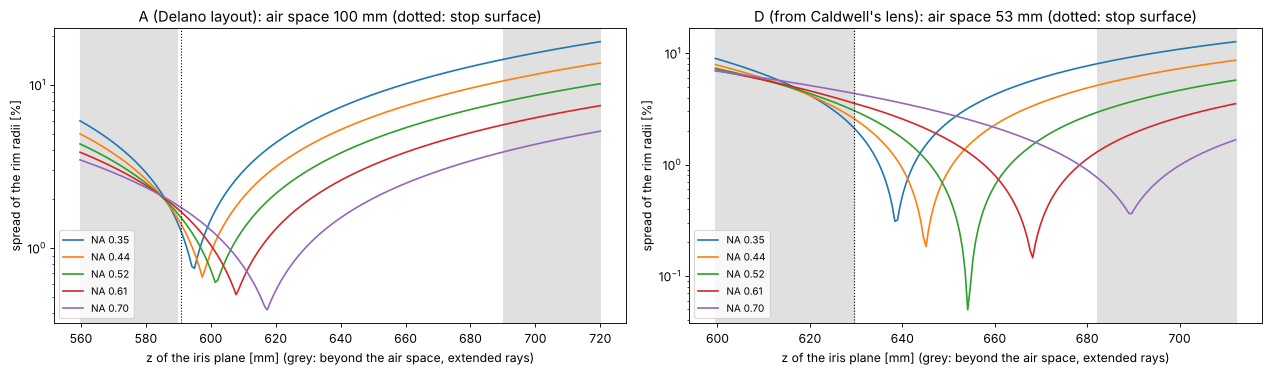

In [16]:
def air_space(system):
    """z of the first and the last surface of the air space that holds the stop."""
    k, air = system.stop_index, system._is_gap
    a = k
    while a > 0 and air(system.n[a]):
        a -= 1
    b = k
    while b < len(system.surfaces) - 1 and air(system.n[b + 1]):
        b += 1
    return system.vertex_z[a], system.vertex_z[b]


def rim_rays(system, field, na, n_phi=36, n_rho=80):
    """Points and directions, in the air space of the stop, of the rays that leave at the angle
    arcsin(na) to the chief ray on the image side (half the pupil: the y-z plane is a plane of
    symmetry)."""
    k = system.stop_index
    seg = k + 1 if system._is_gap(system.n[k + 1]) else k
    R, F = np.meshgrid(np.linspace(0, 1.15, n_rho), np.linspace(0, np.pi, n_phi))
    b = system.trace(system.rays(field, (R*np.sin(F)).ravel(), (R*np.cos(F)).ravel(), aim=True), clip=False)
    D_img = system._image_hits(b)[1]
    sin_t = np.linalg.norm(np.cross(D_img, D_img[0]), axis=1).reshape(n_phi, n_rho)
    P = np.asarray(b.points[seg]).reshape(n_phi, n_rho, 3)
    D = np.asarray(b.directions[seg]).reshape(n_phi, n_rho, 3)
    j = np.array([np.searchsorted(row, na) for row in sin_t])
    rows = np.arange(n_phi)
    w = ((na - sin_t[rows, j - 1])/(sin_t[rows, j] - sin_t[rows, j - 1]))[:, None]
    return (1 - w)*P[rows, j - 1] + w*P[rows, j], (1 - w)*D[rows, j - 1] + w*D[rows, j]


def iris_mismatch(system, na, zs, fields=(0.0, 0.5, 0.75, 1.0)):
    """Spread of the radii of the rim rays of all fields in the planes zs, relative to their mean:
    zero where one centred circle (an iris) cuts the same NA from every field."""
    rims = [rim_rays(system, f*h, na) for f in fields]
    out = []
    for z in zs:
        r = np.array([np.hypot(*(P + ((z - P[:, 2])/D[:, 2])[:, None]*D)[:, :2].T) for P, D in rims])
        out.append((np.max(np.abs(r - r.mean()))/r.mean(), r.mean()))
    return np.array(out)


NAS = np.linspace(0.35, 0.7, 5)
fig, axes = plt.subplots(1, 2, figsize=(16, 4.8))
for ax, (name, s) in zip(axes, [("A (Delano layout)", design), ("D (from Caldwell's lens)", caldwell)]):
    s = s.copy()
    s.ray_aiming = True
    for i, x in enumerate(s.surfaces):
        if i != s.stop_index:
            x.semi_diameter = None  # the rays beyond the full NA, for the virtual planes
    z0, z1 = air_space(s)
    zs = np.linspace(z0 - 30, z1 + 30, 201)
    ax.axvspan(zs[0], z0, color="0.88")
    ax.axvspan(z1, zs[-1], color="0.88")
    print(f"{name}: air space z = {z0:.1f} to {z1:.1f} mm, stop surface at {s.vertex_z[s.stop_index]:.1f} mm")
    for na in NAS:
        m = iris_mismatch(s, na, zs)
        i = np.argmin(m[:, 0])
        at_stop = m[np.argmin(np.abs(zs - s.vertex_z[s.stop_index])), 0]
        ax.semilogy(zs, 100*m[:, 0], label=f"NA {na:.2f}")
        print(f"  NA {na:.2f}: best iris plane z = {zs[i]:.1f} mm, radius {m[i, 1]:.1f} mm, spread "
              f"{100*m[i, 0]:.2f} % (at the stop surface {100*at_stop:.2f} %)")
    ax.axvline(s.vertex_z[s.stop_index], color="k", ls=":", lw=1)
    ax.set_xlabel("z of the iris plane [mm] (grey: beyond the air space, extended rays)")
    ax.set_ylabel("spread of the rim radii [%]")
    ax.set_title(f"{name}: air space {z1 - z0:.0f} mm (dotted: stop surface)")
    ax.legend(fontsize=9)
fig.tight_layout()

For both lenses the best plane for the iris moves towards the wafer as the
NA grows: by 22 mm in the lens from the Delano layout (from 595 to 617 mm,
4 to 27 mm behind the stop surface) and by 51 mm in the lens from
Caldwell's start (from 638 to 690 mm). In its best plane a circle cuts the
same NA from all field points to 0.05 to 0.75 % (of the radius); on the
stop surface itself the spread is 1.3 to 1.8 % and 2.2 to 4.4 %: the stop
of the optimizer, the surface where the paraxial chief ray crosses the
axis, is not where the real rays of one NA meet.

The lens from the Delano layout has room: its 100 mm air space holds all
the best planes, and an iris that moves by 22 mm with the NA fits, as does
a fixed iris at about 605 mm with a spread below 1 %. The lens from
Caldwell's start does not: at NA 0.7 its best plane lies 7.5 mm beyond the
end of its 53 mm air space, inside the next lens, and at the end of the
air space the spread is about 1 %. The air space operand of section 5 asks
for room around the stop surface, not around the planes where an iris
works; a better rule puts the room around the best planes of the NAs in
use, or constrains the spread itself.

## 10. What the diagram did and what it did not

- **First order is exact.** The layout of section 3 fixes magnification,
  NA, length, telecentricity and the flat Petzval field before a single
  surface is bent; thickening keeps all of it, and the optimizer only
  has to hold it (the solves for length and NA, small residuals for
  telecentricity and magnification).
- **The correction moves the layout.** The corrected lens keeps the
  telecentric ends and the bulge at the stop, but makes the first group one
  long waist and removes the second (section 8).
- **The start matters, and a corrected start beats a drawn one.** Two of
  four starts failed outright (section 5.1). Caldwell's corrected lens of
  NA 0.56, opened to NA 0.7 and the larger field, ended better than the
  Delano layout at every step: 0.11–0.24 against 0.22–0.64 waves with five
  aspheres, 0.01–0.05 against 0.03–0.08 with ten.
- **The real NA, not the paraxial one.** Corrected at a paraxial NA of
  0.7, the lens from the layout had a real NA of 0.64, and an earlier
  version of this notebook reported 0.10–0.25 waves for it. At the real
  NA of 0.7 the same pipeline gives 0.22–0.64 waves.
- **The merit function and the aspheres are the bigger levers.** The
  wavefront on a dense pupil grid instead of transverse ray errors halves
  the wavefront error, if distortion and telecentricity are weighted so
  that they are not traded away. Five more aspheres where
  `predicted_gain()` ranks them, at the ends of the lens, and a polish with
  the clearances as constraints gain a factor of five to ten, to the
  diffraction limit (sections 6 and 7). Given from the first stage on
  instead, the same aspheres led the Delano layout into a dead end.
- **Where the aspheres go decides what they correct.** The ranking follows
  the pupil closeness: aperture aberrations at the stop, field aberrations
  at the reticle and the wafer; and the asphere that acts weakest (on the
  first surface) is the one that gains most.
- **Telecentricity of which ray?** Without ray aiming the "chief ray" of the
  optimizer starts towards the paraxial entrance pupil; at NA 0.7 the
  pupil aberrations put it tens of mrad away from the ray through the centre
  of the stop. The `aim=True` operands trace the real chief ray (aimed at
  the stop centre by Newton's method, all fields in one trace), at about
  twice the cost of an evaluation.
- **The stop is a plane only for one NA.** The best plane for an iris moves
  by 20 to 50 mm between NA 0.35 and 0.7 and is not the stop surface of the
  optimizer; whether a design has room for it is a check of its own
  (section 9).
- **Analytic Jacobians make this affordable.** Differential ray tracing
  gives the Jacobian of the 96 variables in about a second instead of 17,
  so a run from a start takes under an hour, and four starts, two asphere
  sets and the polish fit into a day.
- **Not a production design.** Real KrF lenses of this NA have about 30
  elements; many lenses sit at the 10 mm limit and many air spaces at
  1 mm, and nothing was toleranced. Distortion and wavefront error are only
  controlled at the sampled fields.

Exercises: sample more fields for distortion; put the air space operand
around the best iris planes of section 9; split the long first waist into
fewer, stronger lenses (draw it into the sketch); use a smaller field or a
lower NA and see how the residual wavefront error drops; follow the
diagram through the stages of the optimization
(`DelanoDiagram.from_system()`).

In [17]:
print(f"run time {time.time() - t_start:.0f} s")

run time 132 s


## References

- E. Delano, "First-order design and the y, ybar diagram", Appl. Opt. 2, 1251-1256 (1963).
- R. V. Shack, "Analytic system design with pencil and ruler", Proc. SPIE 39, 127 (1973).
- F. J. López-López, *The application of the Delano y-ybar diagram to optical design*, Ph.D. dissertation, University of Arizona (1973).
- R. Kingslake and R. B. Johnson, *Lens Design Fundamentals*, 2nd ed., Academic Press (2010).
- T. Matsuyama, Y. Ohmura and D. M. Williamson, "The lithographic lens: its history and evolution", Proc. SPIE 6154, 615403 (2006).
- G. H. Spencer, "A flexible automatic lens correction procedure", Appl. Opt. 2, 1257-1264 (1963) (constraints with Lagrange multipliers).
